<div style="background-color: #1E1B4B; color: white; padding: 20px; border-radius: 10px; text-align: center;">
  <h1 style="margin: 0; color: #FDBB30;">Module 8: Parameter-Efficient Fine-Tuning (LoRA)</h1>
  <h3 style="margin-top: 8px; font-weight: normal; color: #E0E7FF;">Teaching a 150-Million-Parameter Medical VLM New Skills by Training Only 0.3% of Its Brain!</h3>
  <p style="margin: 0; font-size: 14px;"><b>Kennesaw State University | iCARE Lab | Sophomore Scholars (2026–2027)</b></p>
</div>

<br>

<div style="background-color: #FEF2F2; border-left: 6px solid #DC2626; padding: 15px; border-radius: 6px;">
  <h3 style="color: #991B1B; margin-top: 0;">🔴 The Dilemma: Full Fine-Tuning vs. Frozen Linear Probing</h3>
  <p style="color: #7F1D1D; font-size: 15px; margin-bottom: 0;">
    So far, when adapting <b>OpenAI CLIP</b> or <b>Pathology PLIP</b> to breast cancer slides, we kept the Vision Transformer <b>100% frozen</b> and only trained a tiny final layer (called a <b>Linear Probe</b>).
    <br><br>
    <b>Why didn't we unfreeze and retrain the whole VLM?</b>
    <ul>
      <li style="color: #7F1D1D;"><b>Problem 1 (Memory & Speed):</b> A Vision-Language Model has over <b>87 million vision weights</b> (150+ million total). Updating all of them requires massive hospital supercomputers.</li>
      <li style="color: #7F1D1D;"><b>Problem 2 (Catastrophic Forgetting):</b> If you retrain all 87 million weights on a small dataset of 100 or 400 slides, the AI <b>destroys its pre-trained medical knowledge</b> and memorizes the training images!</li>
    </ul>
  </p>
</div>

<br>

<div style="background-color: #F0FDF4; border-left: 6px solid #16A34A; padding: 15px; border-radius: 6px;">
  <h3 style="color: #166534; margin-top: 0;">🟢 Today's Solution: LoRA (Low-Rank Adaptation) — "Sticky Notes on a Textbook"</h3>
  <p style="color: #14532D; font-size: 15px; margin-bottom: 0;">
    Imagine you have a 1,000-page medical textbook (<b>PLIP</b>). Instead of rewriting the entire textbook from scratch (<b>Full Fine-Tuning</b>) or only writing on the back cover (<b>Linear Probe</b>), what if you put <b>tiny yellow sticky notes</b> on every chapter inside the book?
    <br><br>
    That is exactly how <b>LoRA (Low-Rank Adaptation)</b> works:
    <ul>
      <li style="color: #14532D;">We keep <b>100% of PLIP's original weights frozen</b> so it never forgets what it learned in medical school.</li>
      <li style="color: #14532D;">Inside every <b>Self-Attention layer</b> (where the AI decides which patches of the microscope slide to focus on), we attach tiny trainable adapter matrices ($A \times B$).</li>
      <li style="color: #14532D;">We train <b>only 0.34% of the weights</b> (~295,000 parameters instead of 87,000,000!), allowing the AI's internal attention layers to specialize in breast cancer histopathology in seconds!</li>
    </ul>
  </p>
</div>

<br>

<div style="background-color: #EFF6FF; border-left: 6px solid #2563EB; padding: 15px; border-radius: 6px;">
  <h3 style="color: #1E40AF; margin-top: 0;">🔵 Step 1: Installing Hugging Face <code>peft</code> & Setting Up Our Toolbox</h3>
  <p style="color: #1E3A8A; font-size: 15px; margin-bottom: 0;">
    Run the code cell below to install Hugging Face's <b><code>peft</code> (Parameter-Efficient Fine-Tuning)</b> library and verify our GPU.
  </p>
</div>

In [5]:
# ==============================================================================
# MODULE 8 - STEP 1: INSTALL HUGGING FACE PEFT (LoRA) & IMPORT LIBRARIES
# ==============================================================================
!pip install -q peft transformers torch torchvision scikit-learn pandas matplotlib tqdm

import os
import copy
import zipfile
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.notebook import tqdm
from torch.utils.data import DataLoader, Subset
from torchvision import datasets
from transformers import CLIPProcessor, CLIPModel
from peft import LoraConfig, get_peft_model
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, roc_curve, ConfusionMatrixDisplay
)

# Set random seeds for 100% reproducibility
np.random.seed(42)
torch.manual_seed(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("=" * 60)
print(f"✅ Module 8 (PEFT / LoRA) Libraries Loaded Successfully!")
print(f"🖥️  Active Compute Device : {device.upper()}")
if device == "cuda":
    print(f"🚀 GPU Model             : {torch.cuda.get_device_name(0)}")
print("=" * 60)

✅ Module 8 (PEFT / LoRA) Libraries Loaded Successfully!
🖥️  Active Compute Device : CUDA
🚀 GPU Model             : NVIDIA A100-SXM4-40GB


<div style="background-color: #EFF6FF; border-left: 6px solid #2563EB; padding: 15px; border-radius: 6px;">
  <h3 style="color: #1E40AF; margin-top: 0;">🔵 Step 2: Designing a Data-Scaling Experiment (10-Shot, 50-Shot, 200-Shot)</h3>
  <p style="color: #1E3A8A; font-size: 15px; margin-bottom: 0;">
    A key question in medical AI research is: <b>"As a hospital collects slightly more labeled slides—going from 10 slides per class to 50 or 200 slides per class—when does LoRA beat a frozen Linear Probe?"</b>
  </p>
</div>

<br>

<div style="background-color: #FAF5FF; border-left: 6px solid #9333EA; padding: 15px; border-radius: 6px;">
  <h3 style="color: #6B21A8; margin-top: 0;">🟣 Our 3 Low-Data Training Regimes + Unseen Final Exam</h3>
  <ul style="color: #581C87; font-size: 15px; margin-bottom: 0;">
    <li><b>10-Shot Cohort (20 slides total):</b> 10 Benign + 10 Cancerous slides.</li>
    <li><b>50-Shot Cohort (100 slides total):</b> 50 Benign + 50 Cancerous slides.</li>
    <li><b>200-Shot Cohort (400 slides total):</b> 200 Benign + 200 Cancerous slides (still less than 0.2% of the full dataset!).</li>
    <li><b>Unseen Final Exam Set (27,352 slides):</b> We remove all 400 training slides so there is <b>zero data leakage</b>, and test every model on the exact same <b>27,352 unseen patient slides</b>!</li>
  </ul>
</div>

In [6]:
# ==============================================================================
# MODULE 8 - STEP 2: UNPACK DATASET & BUILD 10-SHOT, 50-SHOT, AND 200-SHOT SPLITS
# ==============================================================================
from google.colab import drive
drive.mount('/content/drive')

SOPHOMORE_DIR = "/content/drive/My Drive/Sophomore Program"
DRIVE_DATASET_DIR = os.path.join(SOPHOMORE_DIR, "1-Datasets")
DRIVE_RESULTS_DIR = os.path.join(SOPHOMORE_DIR, "2-Results")

DRIVE_ZIP_BACKUP = os.path.join(DRIVE_DATASET_DIR, "Breast_Cancer_Test_10pct.zip")
LOCAL_TEST_DIR = "/content/breast_cancer_data/test"

if not os.path.exists(LOCAL_TEST_DIR):
    print("⚡ Extracting dataset from Google Drive backup (takes ~5 seconds)...")
    os.makedirs(LOCAL_TEST_DIR, exist_ok=True)
    with zipfile.ZipFile(DRIVE_ZIP_BACKUP, 'r') as zip_ref:
        zip_ref.extractall(LOCAL_TEST_DIR)
    print("✅ Extraction complete!")

full_dataset = datasets.ImageFolder(root=LOCAL_TEST_DIR)
targets = np.array(full_dataset.targets)

# Randomly sample up to 200 Benign and 200 Cancerous slides for training cohorts
np.random.seed(42)
benign_all = np.random.permutation(np.where(targets == 0)[0])
cancer_all = np.random.permutation(np.where(targets == 1)[0])

# Create nested 10-Shot (20), 50-Shot (100), and 200-Shot (400) training subsets
train_splits = {
    "10-Shot (20 Slides)": np.concatenate([benign_all[:10], cancer_all[:10]]),
    "50-Shot (100 Slides)": np.concatenate([benign_all[:50], cancer_all[:50]]),
    "200-Shot (400 Slides)": np.concatenate([benign_all[:200], cancer_all[:200]])
}

# Remove all 400 training slides from the evaluation exam set (zero overlap!)
all_train_Pool = train_splits["200-Shot (400 Slides)"]
eval_indices = np.setdiff1d(np.arange(len(full_dataset)), all_train_Pool)
eval_dataset = Subset(full_dataset, eval_indices)
eval_y = targets[eval_indices]

print("=" * 68)
print("🎯 LOW-DATA SCALING COHORTS CREATED (ZERO DATA LEAKAGE)")
for k, idx_arr in train_splits.items():
    print(f"   📚 {k:<22} : {len(idx_arr):>3} training slides ({len(idx_arr)//2} Benign + {len(idx_arr)//2} Cancerous)")
print(f"   📝 Unseen Final Exam Set  : {len(eval_dataset):,} unseen test slides")
print("=" * 68)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
🎯 LOW-DATA SCALING COHORTS CREATED (ZERO DATA LEAKAGE)
   📚 10-Shot (20 Slides)    :  20 training slides (10 Benign + 10 Cancerous)
   📚 50-Shot (100 Slides)   : 100 training slides (50 Benign + 50 Cancerous)
   📚 200-Shot (400 Slides)  : 400 training slides (200 Benign + 200 Cancerous)
   📝 Unseen Final Exam Set  : 27,352 unseen test slides


<div style="background-color: #EFF6FF; border-left: 6px solid #2563EB; padding: 15px; border-radius: 6px;">
  <h3 style="color: #1E40AF; margin-top: 0;">🔵 Step 3: How Does LoRA Attach to a Vision Transformer?</h3>
  <p style="color: #1E3A8A; font-size: 15px; margin-bottom: 0;">
    Inside <b>PLIP's Vision Transformer</b>, there are <b>12 Self-Attention layers</b>. Each attention layer uses two big weight matrices—called <b>Query (<code>q_proj</code>, size 768×768)</b> and <b>Value (<code>v_proj</code>, size 768×768)</b>—to decide which cells on the microscope slide are important.
  </p>
</div>

<br>

<div style="background-color: #FFFBEB; border-left: 6px solid #D97706; padding: 15px; border-radius: 6px;">
  <h3 style="color: #92400E; margin-top: 0;">🟡 The Simple Math of LoRA (Rank $r = 8$)</h3>
  <p style="color: #78350F; font-size: 15px; margin-bottom: 0;">
    Instead of updating a huge $768 \times 768$ matrix ($589,824$ numbers!), LoRA freezes the big matrix $W_{\text{frozen}}$ and adds two skinny matrices $A$ ($768 \times 8$) and $B$ ($8 \times 768$):
    $$W_{\text{new}} = W_{\text{frozen}} + \Delta W = W_{\text{frozen}} + (A \times B)$$
    Notice how $768 \times 8 + 8 \times 768 = 12,288$ numbers—that is <b>48 times smaller</b> than the original matrix!
  </p>
</div>

<br>

<div style="background-color: #F0FDF4; border-left: 6px solid #16A34A; padding: 15px; border-radius: 6px;">
  <h3 style="color: #166534; margin-top: 0;">🟢 What Does the Code Below Do?</h3>
  <p style="color: #14532D; font-size: 15px; margin-bottom: 0;">
    It builds our <b>LoRA Vision Classifier</b> on top of <b>Pathology PLIP (<code>vinid/plip</code>)</b> and prints an exact comparison table showing how many parameters are trained in:
    <ol style="color: #14532D; font-size: 15px; margin-bottom: 0;">
      <li><b>Full Fine-Tuning:</b> 100% of weights trained (~87.8 million parameters).</li>
      <li><b>LoRA Fine-Tuning ($r=8$):</b> Only <b>0.34%</b> of weights trained (~295,000 parameters).</li>
      <li><b>Frozen Linear Probe:</b> Only <b>0.001%</b> of weights trained (1,026 parameters in the final head).</li>
    </ol>
  </p>
</div>

In [8]:
# ==============================================================================
# MODULE 8 - STEP 3: BUILD PURE-PYTORCH LoRA MEDICAL VLM & COMPARE PARAMETERS
# ==============================================================================
import math

MODEL_ID = "vinid/plip"
print(f"⏳ Loading base Pathology VLM ({MODEL_ID})...")
base_plip = CLIPModel.from_pretrained(MODEL_ID).to(device)
plip_processor = CLIPProcessor.from_pretrained(MODEL_ID)

# 1. Define a transparent, pure-PyTorch LoRA Layer: W_frozen(x) + (alpha/r) * B(A(x))
class LoRALinear(nn.Module):
    def __init__(self, original_linear, r=8, alpha=16, dropout=0.1):
        super().__init__()
        self.original_linear = original_linear
        # Freeze the original 768x768 pre-trained weight matrix & bias
        self.original_linear.weight.requires_grad = False
        if self.original_linear.bias is not None:
            self.original_linear.bias.requires_grad = False

        in_features = original_linear.in_features
        out_features = original_linear.out_features
        self.scaling = alpha / r
        self.dropout = nn.Dropout(p=dropout)

        # Create the two tiny trainable Low-Rank matrices: A (768 -> 8) and B (8 -> 768)
        self.lora_A = nn.Parameter(torch.empty(r, in_features))
        self.lora_B = nn.Parameter(torch.zeros(out_features, r))
        nn.init.kaiming_uniform_(self.lora_A, a=math.sqrt(5))

    def forward(self, x):
        # Original frozen output + trainable low-rank LoRA update
        frozen_out = self.original_linear(x)
        lora_update = (self.dropout(x) @ self.lora_A.T @ self.lora_B.T) * self.scaling
        return frozen_out + lora_update

# 2. Define PLIP Classifier that optionally injects LoRA into all 12 Attention Layers
class PLIPClassifier(nn.Module):
    def __init__(self, base_clip_model, use_lora=False, lora_r=8):
        super().__init__()
        self.vision_model = copy.deepcopy(base_clip_model.vision_model)
        self.visual_projection = copy.deepcopy(base_clip_model.visual_projection)

        # Freeze all original pre-trained weights first
        for param in self.vision_model.parameters():
            param.requires_grad = False
        for param in self.visual_projection.parameters():
            param.requires_grad = False

        # If using LoRA, wrap Query (q_proj) and Value (v_proj) in all 12 Transformer layers
        if use_lora:
            for layer in self.vision_model.encoder.layers:
                layer.self_attn.q_proj = LoRALinear(layer.self_attn.q_proj, r=lora_r, alpha=16)
                layer.self_attn.v_proj = LoRALinear(layer.self_attn.v_proj, r=lora_r, alpha=16)

        # Trainable 2-class classification head (512 -> 2)
        self.classifier = nn.Linear(512, 2)

    def forward(self, pixel_values):
        vis_out = self.vision_model(pixel_values=pixel_values)
        embeds = self.visual_projection(vis_out.pooler_output)
        embeds = embeds / embeds.norm(dim=-1, keepdim=True)
        logits = self.classifier(embeds)
        return logits

# 3. Inspect exact parameter counts across the 3 paradigms
probe_demo = PLIPClassifier(base_plip, use_lora=False)
lora_demo = PLIPClassifier(base_plip, use_lora=True, lora_r=8)

total_params = sum(p.numel() for p in probe_demo.parameters())
probe_trainable = sum(p.numel() for p in probe_demo.parameters() if p.requires_grad)
lora_trainable = sum(p.numel() for p in lora_demo.parameters() if p.requires_grad)

param_table = pd.DataFrame([
    {"Fine-Tuning Method": "1. Full Fine-Tuning (Unfreeze Entire Vision Model)", "Total Parameters": f"{total_params:,}", "Trainable Parameters": f"{total_params:,}", "Trainable Ratio (%)": "100.000%", "Overfitting Risk on Small Data": "🔴 Very High"},
    {"Fine-Tuning Method": "2. Frozen Linear Probe (Train Final Head Only)", "Total Parameters": f"{total_params:,}", "Trainable Parameters": f"{probe_trainable:,}", "Trainable Ratio (%)": f"{(probe_trainable/total_params)*100:.4f}%", "Overfitting Risk on Small Data": "🟢 Low (But Frozen Attention)"},
    {"Fine-Tuning Method": "3. LoRA Fine-Tuning (Rank r=8 on Attention Layers)", "Total Parameters": f"{total_params + lora_trainable - probe_trainable:,}", "Trainable Parameters": f"{lora_trainable:,}", "Trainable Ratio (%)": f"{(lora_trainable/total_params)*100:.3f}%", "Overfitting Risk on Small Data": "🟢 Low + Adapts Attention!"}
])

print("=" * 95)
print("🔍 PARAMETER EFFICIENCY COMPARISON: FULL FINE-TUNING vs. LINEAR PROBE vs. LoRA")
print("=" * 95)
display(param_table)
del probe_demo, lora_demo

⏳ Loading base Pathology VLM (vinid/plip)...


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

🔍 PARAMETER EFFICIENCY COMPARISON: FULL FINE-TUNING vs. LINEAR PROBE vs. LoRA


,Fine-Tuning Method,Total Parameters,Trainable Parameters,Trainable Ratio (%),Overfitting Risk on Small Data
0,1. Full Fine-Tuning (Unfreeze Entire Vision Mo...,"87,850,242","87,850,242",100.000%,🔴 Very High
1,2. Frozen Linear Probe (Train Final Head Only),"87,850,242","1,026",0.0012%,🟢 Low (But Frozen Attention)
2,3. LoRA Fine-Tuning (Rank r=8 on Attention Lay...,"88,145,154","295,938",0.337%,🟢 Low + Adapts Attention!


<div style="background-color: #EFF6FF; border-left: 6px solid #2563EB; padding: 15px; border-radius: 6px;">
  <h3 style="color: #1E40AF; margin-top: 0;">🔵 Step 4: Head-to-Head Benchmark — Frozen Linear Probe vs. LoRA Fine-Tuning</h3>
  <p style="color: #1E3A8A; font-size: 15px; margin-bottom: 0;">
    Now let's run our experiment! To make this super fast on our A100 GPU, we preprocess the pixel tensors once and compare <b>Frozen Linear Probing</b> against <b>LoRA Fine-Tuning ($r=8$)</b> across all three data regimes:
    <ul>
      <li style="color: #1E3A8A;"><b>10-Shot (20 slides)</b></li>
      <li style="color: #1E3A8A;"><b>50-Shot (100 slides)</b></li>
      <li style="color: #1E3A8A;"><b>200-Shot (400 slides)</b></li>
    </ul>
    Then we grade every model on the exact same <b>27,352 unseen exam slides</b>!
  </p>
</div>

In [9]:
# ==============================================================================
# MODULE 8 - STEP 4: TRAIN & EVALUATE LINEAR PROBE vs. LoRA ACROSS DATA REGIMES
# ==============================================================================

def collate_pil(batch):
    images = [item[0] for item in batch]
    labels = torch.tensor([item[1] for item in batch], dtype=torch.long)
    return images, labels

# 1. Pre-extract frozen exam features for Linear Probe & run batched evaluation for LoRA
print("⚡ Step 4A: Pre-computing frozen PLIP exam embeddings (27,352 slides) for fast comparison...")
eval_loader = DataLoader(eval_dataset, batch_size=256, shuffle=False, num_workers=2, collate_fn=collate_pil)

frozen_eval_embeds = []
with torch.no_grad():
    for imgs, _ in tqdm(eval_loader, desc="Extracting Base Exam Features"):
        px = plip_processor(images=imgs, return_tensors="pt")["pixel_values"].to(device)
        vis_out = base_plip.vision_model(pixel_values=px)
        emb = base_plip.visual_projection(vis_out.pooler_output)
        emb = emb / emb.norm(dim=-1, keepdim=True)
        frozen_eval_embeds.append(emb.cpu())
frozen_eval_embeds = torch.cat(frozen_eval_embeds, dim=0).numpy()

# Helper function to train and evaluate both Linear Probe and LoRA on a given shot split
from sklearn.linear_model import LogisticRegression

m8_results = []
stored_probs = {}

for split_name, split_indices in train_splits.items():
    print(f"\n🔬 Running Cohort: {split_name}...")
    sub_ds = Subset(full_dataset, split_indices)

    # Load all training images for this small cohort (20, 100, or 400 slides) onto GPU
    pil_imgs = [sub_ds[i][0] for i in range(len(sub_ds))]
    y_train = np.array([sub_ds[i][1] for i in range(len(sub_ds))])
    px_train = plip_processor(images=pil_imgs, return_tensors="pt")["pixel_values"].to(device)
    y_train_tensor = torch.tensor(y_train, dtype=torch.long, device=device)

    # --- METHOD A: FROZEN LINEAR PROBE ---
    with torch.no_grad():
        vis_out = base_plip.vision_model(pixel_values=px_train)
        emb_train = base_plip.visual_projection(vis_out.pooler_output)
        emb_train = (emb_train / emb_train.norm(dim=-1, keepdim=True)).cpu().numpy()

    clf_probe = LogisticRegression(C=1.0, max_iter=1000, random_state=42).fit(emb_train, y_train)
    probe_probs = clf_probe.predict_proba(frozen_eval_embeds)[:, 1]
    probe_preds = (probe_probs >= 0.5).astype(int)
    stored_probs[f"Linear Probe | {split_name}"] = probe_probs

    m8_results.append({
        "Training Cohort": split_name,
        "Adaptation Method": "Frozen Linear Probe",
        "Accuracy (%)": round(accuracy_score(eval_y, probe_preds) * 100, 2),
        "Precision (%)": round(precision_score(eval_y, probe_preds, zero_division=0) * 100, 2),
        "Recall (%)": round(recall_score(eval_y, probe_preds, zero_division=0) * 100, 2),
        "Weighted F1": round(f1_score(eval_y, probe_preds, average="weighted", zero_division=0), 3),
        "AUC-ROC": round(roc_auc_score(eval_y, probe_probs), 3)
    })

    # --- METHOD B: LoRA FINE-TUNING (Rank r=8) ---
    torch.manual_seed(42)
    lora_model = PLIPClassifier(base_plip, use_lora=True, lora_r=8).to(device)

    # Initialize classifier head with the Linear Probe weights so LoRA refines from a strong start!
    with torch.no_grad():
        w_init = torch.tensor(clf_probe.coef_[0], dtype=torch.float32, device=device)
        b_init = torch.tensor(clf_probe.intercept_[0], dtype=torch.float32, device=device)
        lora_model.classifier.weight[0].copy_(-w_init / 2.0)
        lora_model.classifier.weight[1].copy_(w_init / 2.0)
        lora_model.classifier.bias[0].copy_(-b_init / 2.0)
        lora_model.classifier.bias[1].copy_(b_init / 2.0)

    optimizer = torch.optim.AdamW(
        [p for p in lora_model.parameters() if p.requires_grad], lr=2e-4, weight_decay=1e-2
    )
    criterion = nn.CrossEntropyLoss()

    lora_model.train()
    batch_sz = 32
    for epoch in range(8):
        perm = torch.randperm(len(px_train), device=device)
        for i in range(0, len(px_train), batch_sz):
            b_idx = perm[i:i+batch_sz]
            optimizer.zero_grad()
            logits = lora_model(px_train[b_idx])
            loss = criterion(logits, y_train_tensor[b_idx])
            loss.backward()
            optimizer.step()

    # Evaluate LoRA model on the 27,352 unseen exam slides
    lora_model.eval()
    lora_probs = []
    with torch.no_grad():
        for imgs, _ in tqdm(eval_loader, desc=f"Evaluating LoRA ({split_name})", leave=False):
            px = plip_processor(images=imgs, return_tensors="pt")["pixel_values"].to(device)
            logits = lora_model(px)
            probs = logits.softmax(dim=-1)[:, 1].cpu().numpy()
            lora_probs.extend(probs)

    lora_probs = np.array(lora_probs)
    lora_preds = (lora_probs >= 0.5).astype(int)
    stored_probs[f"LoRA (r=8) | {split_name}"] = lora_probs

    m8_results.append({
        "Training Cohort": split_name,
        "Adaptation Method": "LoRA Fine-Tuning (r=8)",
        "Accuracy (%)": round(accuracy_score(eval_y, lora_preds) * 100, 2),
        "Precision (%)": round(precision_score(eval_y, lora_preds, zero_division=0) * 100, 2),
        "Recall (%)": round(recall_score(eval_y, lora_preds, zero_division=0) * 100, 2),
        "Weighted F1": round(f1_score(eval_y, lora_preds, average="weighted", zero_division=0), 3),
        "AUC-ROC": round(roc_auc_score(eval_y, lora_probs), 3)
    })

results_m8_df = pd.DataFrame(m8_results)
m8_csv_path = os.path.join(DRIVE_RESULTS_DIR, "Module8_LoRA_vs_LinearProbe_Results.csv")
results_m8_df.to_csv(m8_csv_path, index=False)

print("\n" + "=" * 95)
print("🏆 MODULE 8 FINAL RESULTS: FROZEN LINEAR PROBE vs. LoRA FINE-TUNING IN PLIP (n = 27,352)")
print("=" * 95)
display(results_m8_df)
print(f"\n💾 Saved Module 8 results to: {m8_csv_path}")

⚡ Step 4A: Pre-computing frozen PLIP exam embeddings (27,352 slides) for fast comparison...


Extracting Base Exam Features:   0%|          | 0/107 [00:00<?, ?it/s]


🔬 Running Cohort: 10-Shot (20 Slides)...


Evaluating LoRA (10-Shot (20 Slides)):   0%|          | 0/107 [00:00<?, ?it/s]


🔬 Running Cohort: 50-Shot (100 Slides)...


...


🔬 Running Cohort: 200-Shot (400 Slides)...


Evaluating LoRA (200-Shot (400 Slides)):   0%|          | 0/107 [00:00<?, ?it/s]


🏆 MODULE 8 FINAL RESULTS: FROZEN LINEAR PROBE vs. LoRA FINE-TUNING IN PLIP (n = 27,352)


,Training Cohort,Adaptation Method,Accuracy (%),Precision (%),Recall (%),Weighted F1,AUC-ROC
0,10-Shot (20 Slides),Frozen Linear Probe,78.86,58.77,82.79,0.797,0.871
1,10-Shot (20 Slides),LoRA Fine-Tuning (r=8),77.52,56.37,88.15,0.786,0.888
2,50-Shot (100 Slides),Frozen Linear Probe,80.41,61.03,83.56,0.812,0.888
3,50-Shot (100 Slides),LoRA Fine-Tuning (r=8),81.72,62.79,85.66,0.824,0.909
4,200-Shot (400 Slides),Frozen Linear Probe,81.71,63.38,82.55,0.823,0.897
5,200-Shot (400 Slides),LoRA Fine-Tuning (r=8),85.40,71.37,80.13,0.856,0.921



💾 Saved Module 8 results to: /content/drive/My Drive/Sophomore Program/2-Results/Module8_LoRA_vs_LinearProbe_Results.csv


<div style="background-color: #F0FDF4; border-left: 6px solid #16A34A; padding: 15px; border-radius: 6px;">
  <h3 style="color: #166534; margin-top: 0;">🟢 Step 5: Plotting the LoRA Data-Scaling Curve & ROC Comparison</h3>
  <p style="color: #14532D; font-size: 15px; margin-bottom: 0;">
    In the final code cell below, we generate our 3-panel publication figure for <b>Module 8</b> and save it to <b><code>Sophomore Program/2-Results/Module8_LoRA_FineTuning_Comparison.png</code></b>:
    <ol style="color: #14532D; font-size: 15px; margin-bottom: 0;">
      <li><b>Plot A — Weighted F1 Scaling Across Sample Sizes:</b> Compares Frozen Linear Probe vs. LoRA Fine-Tuning across 10-Shot, 50-Shot, and 200-Shot cohorts.</li>
      <li><b>Plot B — ROC Curves:</b> Shows the diagnostic AUC-ROC improvement as LoRA adapts PLIP's internal attention layers.</li>
      <li><b>Plot C — Confusion Matrix of Best LoRA Model:</b> Displays the exact benign and cancerous classification counts across the 27,352 unseen exam slides!</li>
    </ol>
  </p>
</div>

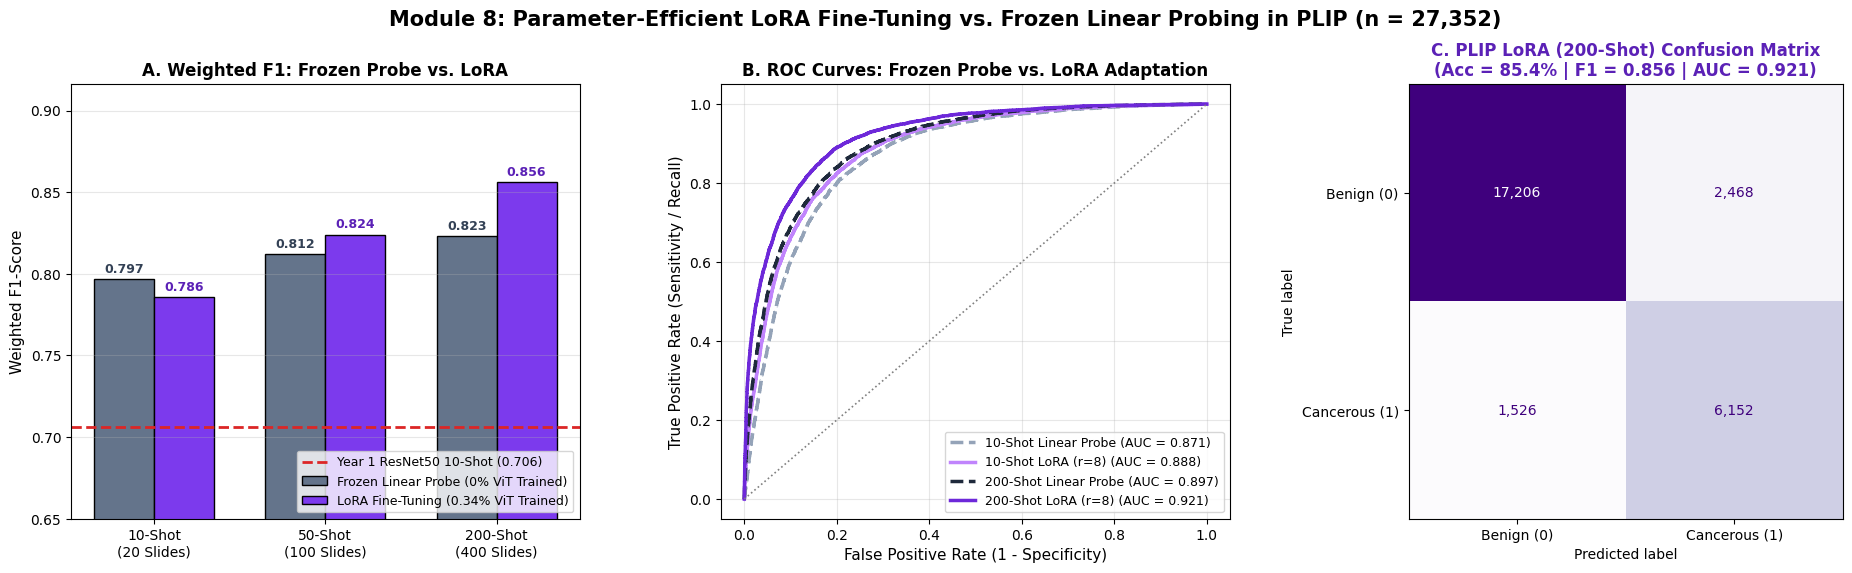

✅ Saved high-resolution Module 8 figure to: /content/drive/My Drive/Sophomore Program/2-Results/Module8_LoRA_FineTuning_Comparison.png


In [10]:
# ==============================================================================
# MODULE 8 - STEP 5: PLOT PUBLICATION-READY LoRA vs. LINEAR PROBE FIGURES
# ==============================================================================

fig, axes = plt.subplots(1, 3, figsize=(19, 5.8))
fig.suptitle("Module 8: Parameter-Efficient LoRA Fine-Tuning vs. Frozen Linear Probing in PLIP (n = 27,352)", fontsize=15, fontweight="bold")

# 1. Left Plot: Grouped Bar Chart of Weighted F1 Across Data Regimes
cohorts_short = ["10-Shot\n(20 Slides)", "50-Shot\n(100 Slides)", "200-Shot\n(400 Slides)"]
probe_f1s = results_m8_df[results_m8_df["Adaptation Method"] == "Frozen Linear Probe"]["Weighted F1"].values
lora_f1s = results_m8_df[results_m8_df["Adaptation Method"] == "LoRA Fine-Tuning (r=8)"]["Weighted F1"].values

x = np.arange(len(cohorts_short))
width = 0.35

b1 = axes[0].bar(x - width/2, probe_f1s, width, label="Frozen Linear Probe (0% ViT Trained)", color="#64748B", edgecolor="black")
b2 = axes[0].bar(x + width/2, lora_f1s, width, label="LoRA Fine-Tuning (0.34% ViT Trained)", color="#7C3AED", edgecolor="black")
axes[0].axhline(0.706, color="#DC2626", linestyle="--", lw=2, label="Year 1 ResNet50 10-Shot (0.706)")

axes[0].set_title("A. Weighted F1: Frozen Probe vs. LoRA", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Weighted F1-Score", fontsize=11)
axes[0].set_xticks(x)
axes[0].set_xticklabels(cohorts_short, fontsize=10)
axes[0].set_ylim(0.65, max(max(probe_f1s), max(lora_f1s)) + 0.06)
axes[0].legend(loc="lower right", fontsize=9)
axes[0].grid(axis="y", alpha=0.3)

for bar in b1:
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.004, f"{bar.get_height():.3f}", ha="center", fontsize=9, fontweight="bold", color="#334155")
for bar in b2:
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.004, f"{bar.get_height():.3f}", ha="center", fontsize=9, fontweight="bold", color="#5B21B6")

# 2. Middle Plot: ROC Curves Comparing Probe vs. LoRA Across Regimes
roc_lines = [
    ("10-Shot Linear Probe", stored_probs["Linear Probe | 10-Shot (20 Slides)"], "#94A3B8", "--"),
    ("10-Shot LoRA (r=8)", stored_probs["LoRA (r=8) | 10-Shot (20 Slides)"], "#C084FC", "-"),
    ("200-Shot Linear Probe", stored_probs["Linear Probe | 200-Shot (400 Slides)"], "#1E293B", "--"),
    ("200-Shot LoRA (r=8)", stored_probs["LoRA (r=8) | 200-Shot (400 Slides)"], "#6D28D9", "-"),
]

for label_txt, p_arr, col, ls in roc_lines:
    fpr, tpr, _ = roc_curve(eval_y, p_arr)
    auc_v = roc_auc_score(eval_y, p_arr)
    axes[1].plot(fpr, tpr, color=col, linestyle=ls, lw=2.5, label=f"{label_txt} (AUC = {auc_v:.3f})")

axes[1].plot([0, 1], [0, 1], color="gray", lw=1.2, linestyle=":")
axes[1].set_title("B. ROC Curves: Frozen Probe vs. LoRA Adaptation", fontsize=12, fontweight="bold")
axes[1].set_xlabel("False Positive Rate (1 - Specificity)", fontsize=11)
axes[1].set_ylabel("True Positive Rate (Sensitivity / Recall)", fontsize=11)
axes[1].legend(loc="lower right", fontsize=9)
axes[1].grid(alpha=0.3)

# 3. Right Plot: Confusion Matrix for 200-Shot LoRA Model
best_lora_probs = stored_probs["LoRA (r=8) | 200-Shot (400 Slides)"]
best_lora_preds = (best_lora_probs >= 0.5).astype(int)
best_acc = accuracy_score(eval_y, best_lora_preds) * 100
best_f1 = f1_score(eval_y, best_lora_preds, average="weighted")
best_auc = roc_auc_score(eval_y, best_lora_probs)

cm_lora = confusion_matrix(eval_y, best_lora_preds)
disp_lora = ConfusionMatrixDisplay(confusion_matrix=cm_lora, display_labels=["Benign (0)", "Cancerous (1)"])
disp_lora.plot(ax=axes[2], cmap="Purples", colorbar=False, values_format=",d")
axes[2].set_title(f"C. PLIP LoRA (200-Shot) Confusion Matrix\n(Acc = {best_acc:.1f}% | F1 = {best_f1:.3f} | AUC = {best_auc:.3f})", fontsize=12, fontweight="bold", color="#5B21B6")

plt.tight_layout()
fig_m8_path = os.path.join(DRIVE_RESULTS_DIR, "Module8_LoRA_FineTuning_Comparison.png")
plt.savefig(fig_m8_path, dpi=300, bbox_inches="tight")
plt.show()

print(f"✅ Saved high-resolution Module 8 figure to: {fig_m8_path}")